# 10.1.2 Escoamento horizontal anular e 10.1.3 padrão bolhas

Mesmo duto da seção 10.1.1 (1000 m, D = 0.1 m, 50 elementos, Galerkin) com
fechamento de padrão **anular** (qL = 0.5 kg/s, qG de 5.0 para 5.5 kg/s) e
de padrão **bolhas** (qG = 0.1 kg/s, qL de 50 para 55 kg/s). As rampas ocorrem
entre 150 e 180 s. Figuras reproduzidas: 10.10 a 10.13, 10.15 e 10.16.

Observação: nos arquivos originais destes casos a fração de gás na entrada tem
condição "conector" sem especificação, que corresponde a gradiente nulo
(von Neumann); o estado inicial gravado só é estacionário com o método de
Galerkin, o que indica que foi esse o método usado nas figuras.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe
from mfsim.plotting import pipe_profiles, legacy_pipe_dict

## Anular (10.1.2)

In [2]:
describe("10.1.2")
case, raw, res = run_case("10.1.2")
compare_states(res, raw)

10.1.2 Escoamento horizontal anular
Mesmo duto com padrão anular fixo. qL=0.5 kg/s; qG sobe de 5.0 para 5.5 kg/s entre 150 e 180 s.
Figuras da tese: Figs. 10.10-10.13


[implicit BDF] steps=219 rejected=6 rhs=2091 jac=16 | 0.7s
tempo de CPU: 0.72 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    7.79e-04       1.00e-02   7.76e-02
   1 twofluid     PT        4.59e-04       1.55e-01   2.96e-03
   1 twofluid     qL        1.40e-02       1.02e-01   1.37e-01
   1 twofluid     qG        1.12e-02       5.01e-01   2.23e-02


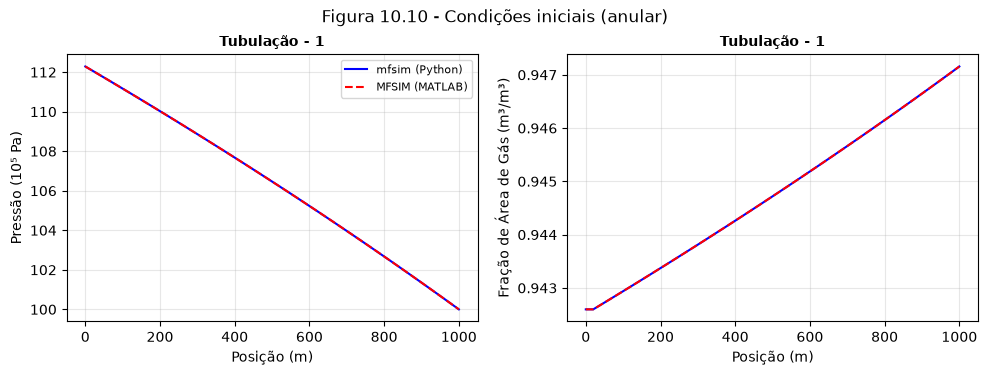

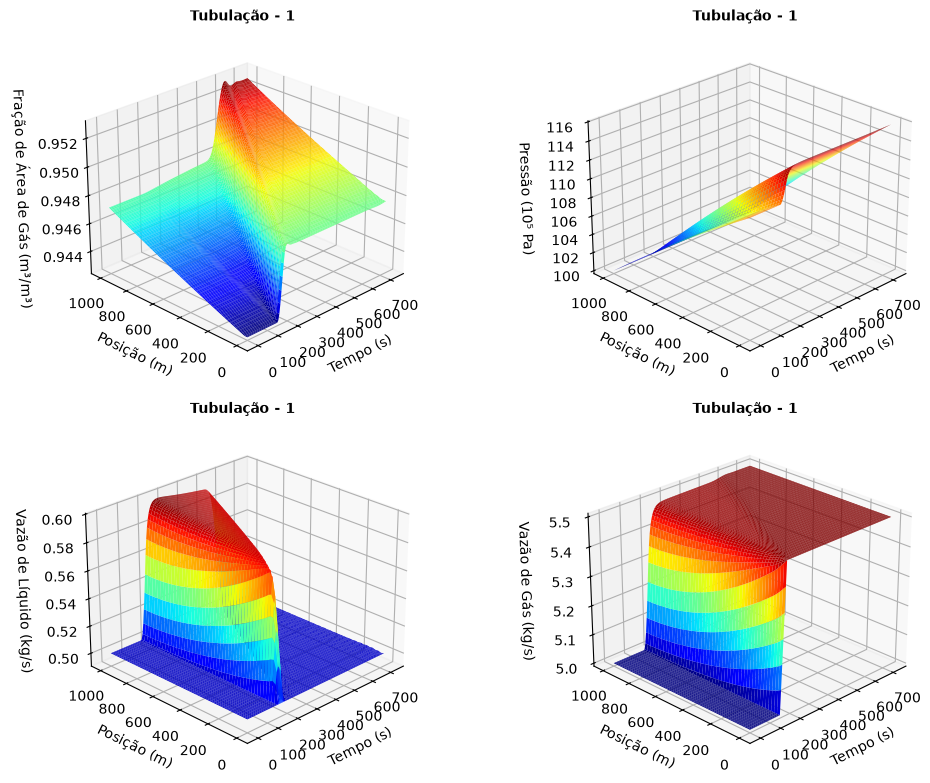

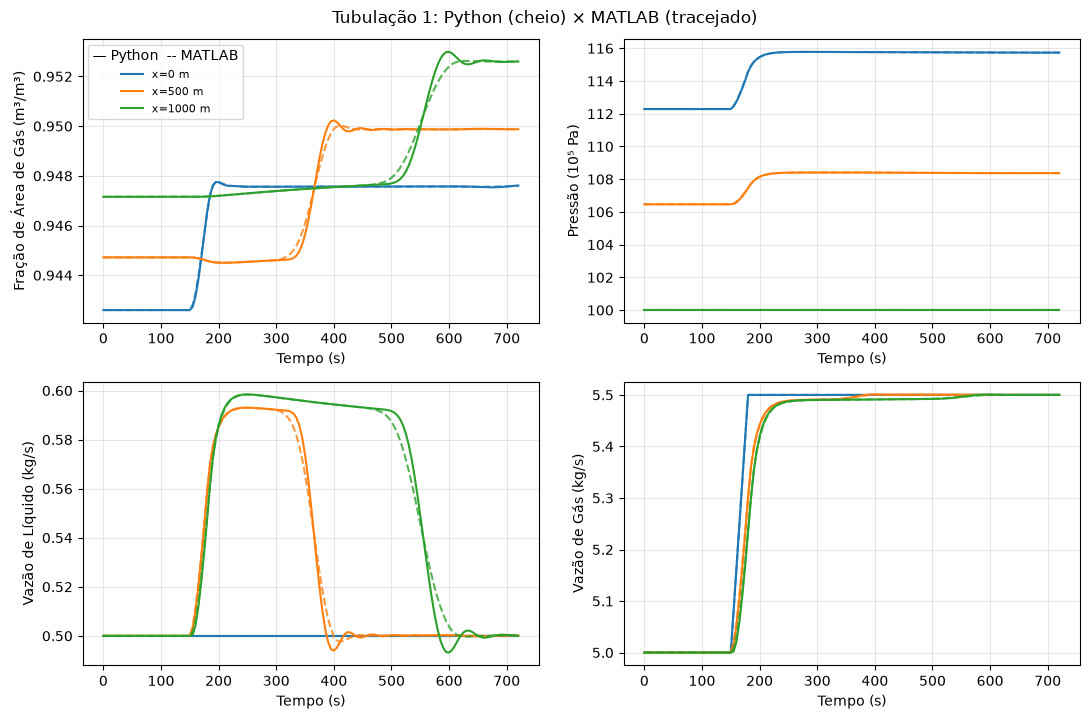

In [3]:
fig = pipe_profiles(res, keys=("P_bar", "alphaG"), it=0, legacy=legacy_pipe_dict(raw, 0))
fig.suptitle("Figura 10.10 - Condições iniciais (anular)", y=1.03); plt.show()
show_pipe(res, raw, 0)

### Sensibilidade de malha (Figuras 10.12 e 10.13)
A tese observa que, a partir de 25 elementos, as variáveis praticamente coincidem.

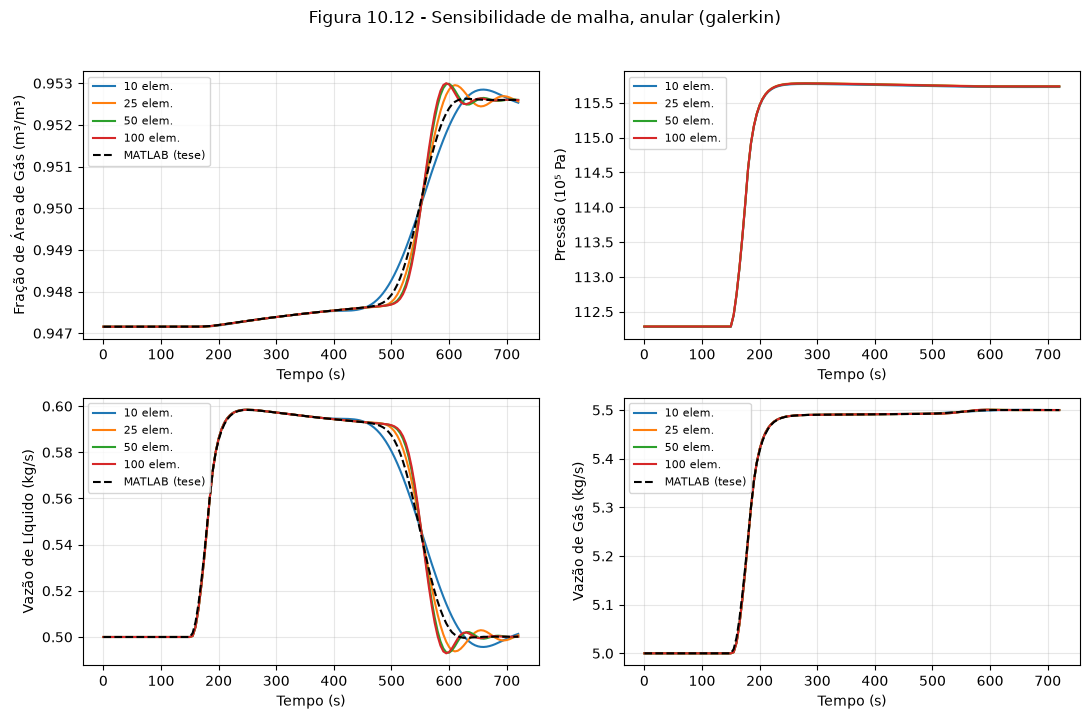

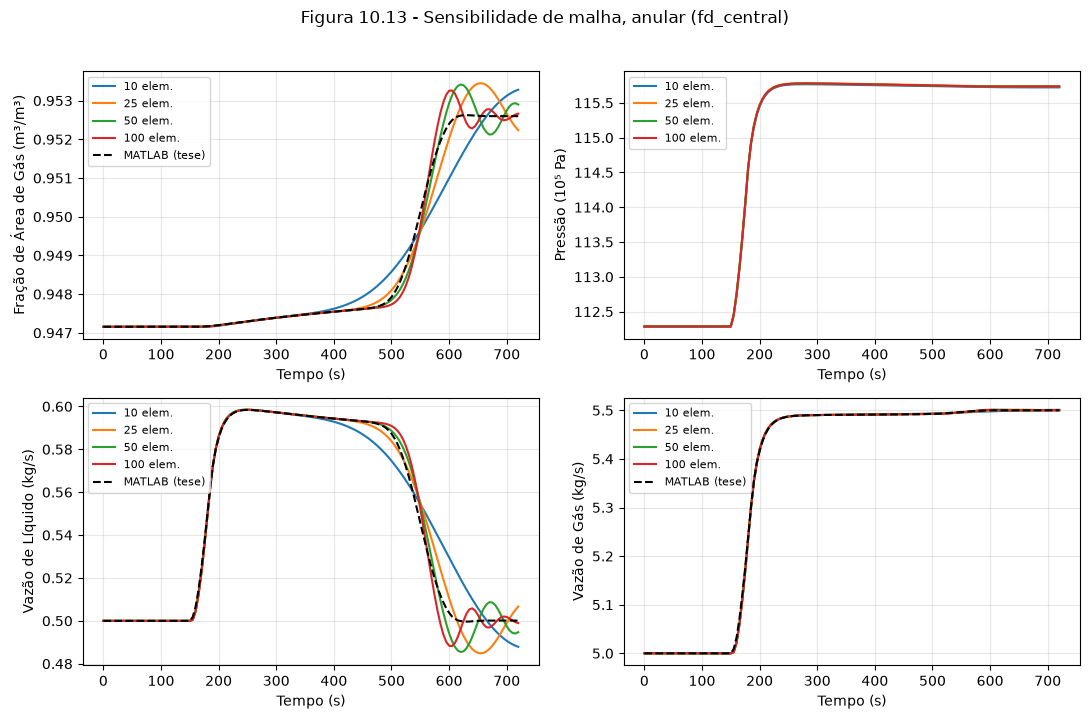

In [4]:
import copy
from mfsim.simulation import steady_state, simulate
from mfsim.plotting import compare_runs
def mesh_runs(case, meshes, method, q0):
    out = {}
    for nel in meshes:
        c = copy.deepcopy(case); c.pipes[0].n_elements = np.array([nel]); c.set_method(method)
        nn = nel + 1
        c.pipes[0].ic = np.stack([np.full(nn, q0[0]), np.full(nn, 1.0), np.full(nn, q0[1]), np.full(nn, q0[2])], axis=1)
        steady_state(c, verbose=False)
        out[f"{nel} elem."] = simulate(c, integrator="implicit", rtol=1e-4, atol=1e-6, progress=False)
    return out
legacy = legacy_pipe_dict(raw, 0)
for method, figname in [("galerkin", "10.12"), ("fd_central", "10.13")]:
    runs = mesh_runs(case, [10, 25, 50, 100], method, (0.94, 0.5, 5.0))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, key in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
        compare_runs(runs, key=key, node=-1 if key != "P_bar" else 0, ax=ax, legacy=legacy if key != "P_bar" else None)
    fig.suptitle(f"Figura {figname} - Sensibilidade de malha, anular ({method})", y=1.02); fig.tight_layout(); plt.show()

## Bolhas (10.1.3)

10.1.3 Escoamento horizontal padrão bolhas
Mesmo duto com padrão bolhas fixo. qG=0.1 kg/s; qL sobe de 50 para 55 kg/s entre 150 e 180 s.
Figuras da tese: Figs. 10.15-10.16


[implicit BDF] steps=144 rejected=7 rhs=7708 jac=101 | 2.6s
tempo de CPU: 2.61 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    2.47e-03       9.88e-03   2.50e-01
   1 twofluid     PT        7.75e-04       1.10e+00   7.03e-04
   1 twofluid     qL        1.18e-01       5.00e+00   2.35e-02
   1 twofluid     qG        1.35e-02       9.98e-03   1.35e+00


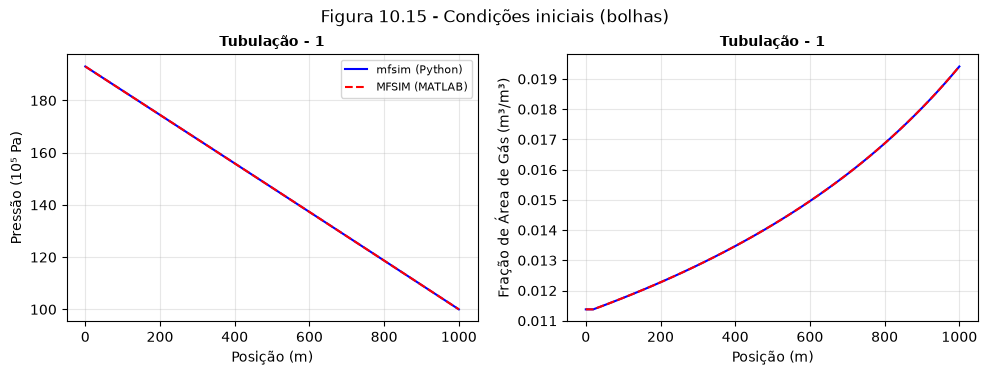

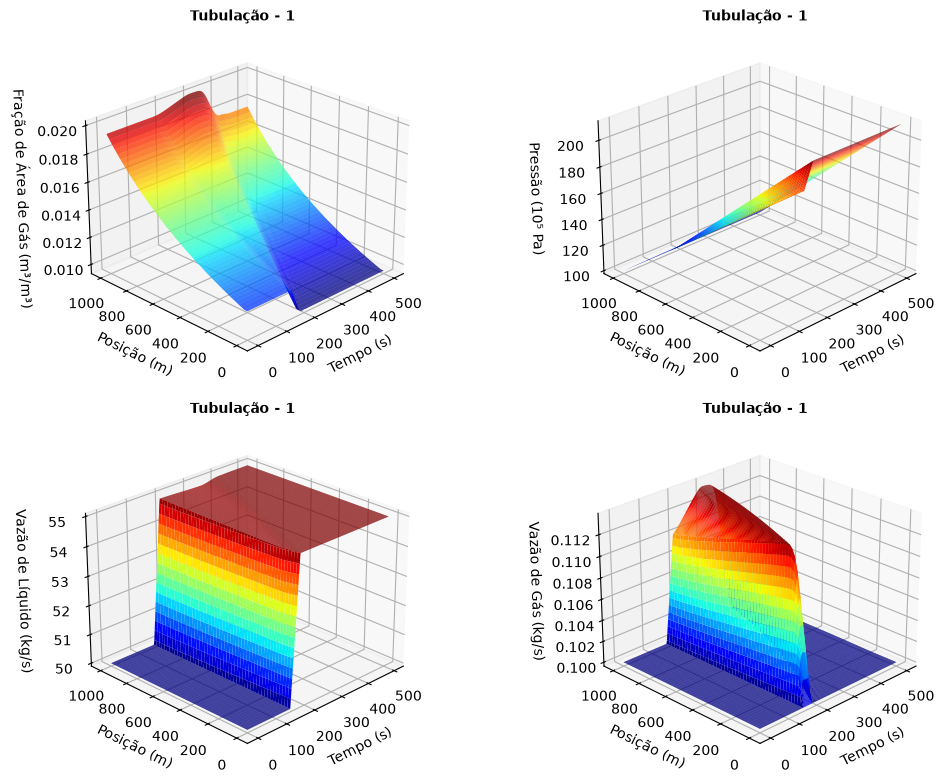

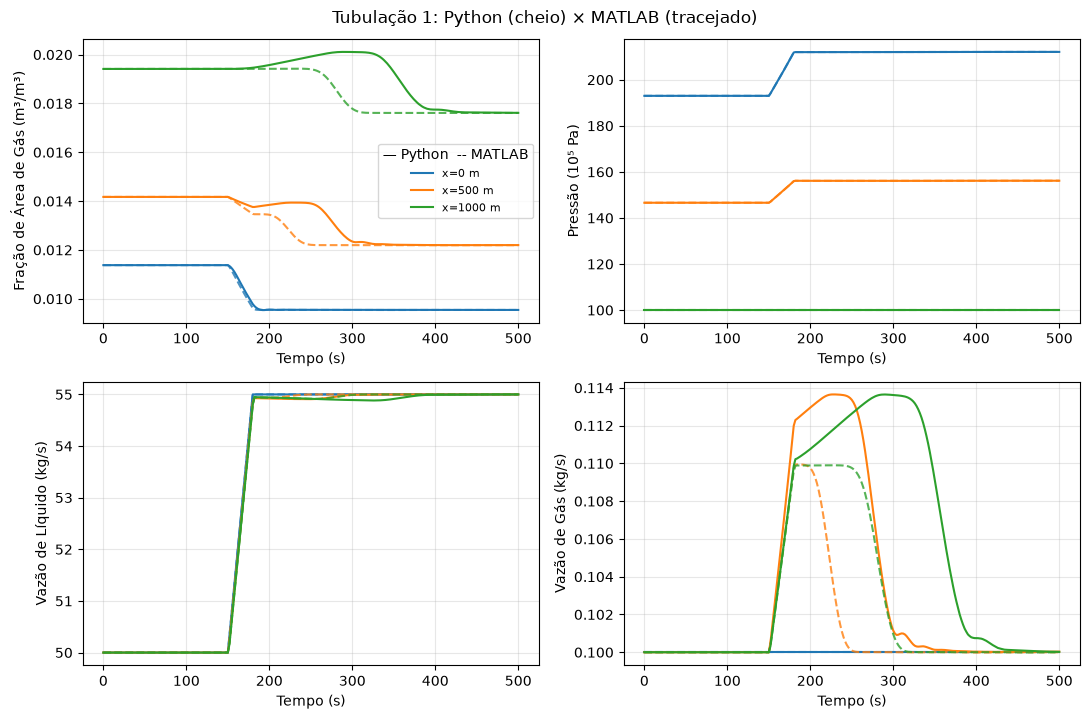

In [5]:
describe("10.1.3")
case, raw, res = run_case("10.1.3")
compare_states(res, raw)
fig = pipe_profiles(res, keys=("P_bar", "alphaG"), it=0, legacy=legacy_pipe_dict(raw, 0))
fig.suptitle("Figura 10.15 - Condições iniciais (bolhas)", y=1.03); plt.show()
show_pipe(res, raw, 0)

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [6]:
from mfsim.notebook_utils import jax_comparison
res_jax = jax_comparison(case, res, rtol=1e-4, atol=1e-6)

JAX: 0.57 s (145 passos; compilação 0.37 s, uma vez por modelo) | numpy: 2.61 s (144 passos) | diferença máxima relativa dos estados 1.6e-04
